# Lifting and Query

Features come per frame; lifting moves them onto the 3D scene. Each 3D point looks itself up in
every keyframe that sees it and averages those features. Afterwards you can search the mesh with
text. This page lifts Talk2DINO features and MobileSAM masks by hand, then queries the mesh the
`semantics` stage lifted.

In [1]:
import contextlib
import io

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import torch
import transformers
import trimesh
import zarr

from collab_splats.pointcloud import PointcloudResult
from collab_splats.preproc.frames import frame_idx_from_path, frame_paths
from collab_splats.semantics import (
    FeatureAutoencoder,
    MobileSAMSegmentation,
    Talk2DinoExtractor,
    read_point_features,
    write_point_features,
)
from collab_splats.semantics.grouping import lift_segments, nearest_labels
from collab_splats.semantics.lifting import lift_features, transfer_features
from collab_splats.utils.io import read_image
from collab_splats.utils.torch_utils import batch_iterator, to_numpy
from collab_splats.utils.visualization import apply_view, camera_view

%run ../tutorial.py

# Hide a harmless checkpoint warning from Talk2DINO
transformers.logging.set_verbosity_error()

scene = tutorial_scene("preproc", "pointcloud", "mesh", "semantics")

## 1. Features per frame

Extract Talk2DINO features for every keyframe, in the point cloud's frame order:

In [2]:
# The point cloud with depth and confidence; lifting needs both
cloud = PointcloudResult.load_zarr(scene.pointcloud_zarr, load_world_points=False)
paths = frame_paths(scene.images_dir, [frame_idx_from_path(p) for p in cloud.image_paths])

extractor = Talk2DinoExtractor()
maps = []

for (batch,) in batch_iterator(4, paths):
    maps.extend(extractor.forward(batch))

stacked = torch.stack(maps)
print(f"{len(maps)} maps of {tuple(maps[0].shape)}, {stacked.nbytes / 2**30:.2f} GiB")

96 maps of (768, 32, 18), 0.16 GiB


## 2. Compressing

Storing a full feature vector per point is costly, so a small autoencoder learns to squeeze each
one into 64 numbers and back. The reconstruction cosine says how well it comes back: 1 is
perfect. It is measured on the training data, so read it as "the fit converged".

In [3]:
features = stacked.numpy()
ae = FeatureAutoencoder(input_dim=features.shape[1], latent_dim=64)
ae.fit(features, epochs=20, target_cosine=0.95)
print(f"reconstruction cosine {ae.recon_cosine:.3f} after {ae.epochs_run} epochs")

# Each frame's map as 64-D codes
ae.cpu()

with torch.no_grad():
    codes = [ae.encode(fmap) for fmap in maps]

reconstruction cosine 0.950 after 8 epochs


## 3. Lifting onto points

`lift_features` projects each point into every frame, keeps the frames whose depth agrees with
the point (so hidden points are skipped), and averages their codes. Saving writes the codes and
the autoencoder; reading decodes back to full features.

In [4]:
point_codes = lift_features(codes.__getitem__, cloud).numpy()

store_path = work_dir("lifting_and_query") / "talk2dino_lifted.zarr"
write_point_features(store_path, point_codes, ae)
point_features = read_point_features(store_path)
print(f"{len(point_features):,} points, {point_features.shape[1]}-D features")

500,000 points, 768-D features


## 4. Lifting masks to groups

Masks lift too. Mask IDs are per frame: the same trunk gets a new ID in every view.
`lift_segments` merges the masks of all keyframes into groups of points that hold across views,
with the same visibility test as `lift_features`:

- 3D overlap merges: masks from two frames join when most points both frames see are shared
- cannot-link: two masks of one frame never join unless they nearly coincide, so neighboring
  trunks do not chain into one group
- features veto: the point features above block merges between groups that look different, and
  label points no mask covered

Segment every keyframe with MobileSAM in `object` mode (see the segmentation page) and lift the
masks:

In [5]:
# Hide model-loading output
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    segmenter = MobileSAMSegmentation(strategy="object", device="cuda")


def frame_masks(i):
    """
    Masks of the point cloud's frame i, computed when the lift asks for them.
    """
    masks, _ = segmenter.segment(read_image(paths[i]))
    return masks


groups = lift_segments(frame_masks, cloud, features=point_features)

n_groups = len(groups.parent)
n_top = int((groups.parent == -1).sum())
print(f"{n_groups} groups ({n_top} top-level) from {len(paths)} keyframes")
print(f"{groups.labeled.mean():.0%} of points labeled by masks, {(groups.labels >= 0).mean():.0%} after fill")

30 groups (27 top-level) from 96 keyframes
86% of points labeled by masks, 99% after fill


Each point's group is the smallest one holding it; a group inside a larger one (a tag on a trunk)
records it as `parent`.

The groups on the points and, carried over by `nearest_labels`, on the stage's mesh:

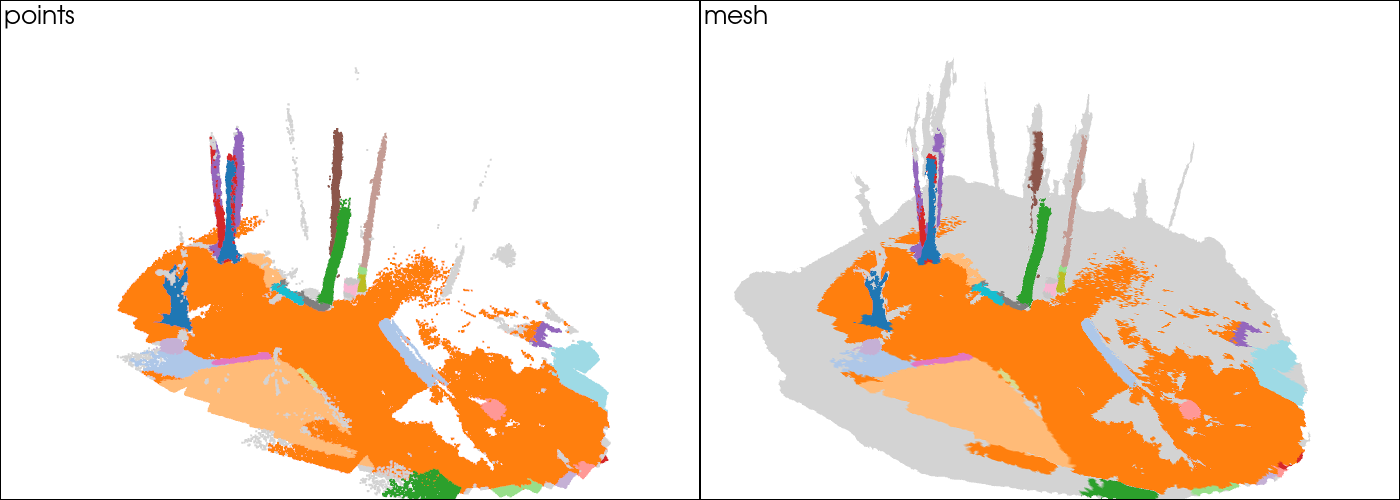

In [6]:
mesh = trimesh.load(scene.outputs["mesh"], process=False)
vertices = np.asarray(mesh.vertices, dtype=np.float32)
points = to_numpy(cloud.points).reshape(-1, 3)
vertex_labels = nearest_labels(vertices, points, groups.labels)

# One tab20 color per group; grey where no group
palette = (plt.cm.tab20(np.arange(n_groups) % 20)[:, :3] * 255).astype(np.uint8)
grey = np.full(3, 211, dtype=np.uint8)
point_colors = np.where(groups.labels[:, None] >= 0, palette[groups.labels.clip(0)], grey)
vertex_colors = np.where(vertex_labels[:, None] >= 0, palette[vertex_labels.clip(0)], grey)

plotter = pv.Plotter(shape=(1, 2), window_size=(1400, 500))
plotter.subplot(0, 0)
plotter.add_text("points", font_size=10)
plotter.add_points(points, scalars=point_colors, rgb=True, point_size=2)
plotter.subplot(0, 1)
plotter.add_text("mesh", font_size=10)
plotter.add_mesh(pv.wrap(mesh), scalars=vertex_colors, rgb=True, lighting=False)
plotter.link_views()
apply_view(plotter, camera_view(cloud.extrinsics, vertices))
plotter.show()

Each color is one group, the same in every view. Grey points belong to no group. On the mesh,
grey also marks surface farther than 5 point spacings from any point, such as the filled ground
and thinly sampled trunks.

## 5. Querying the mesh

The `semantics` stage did the same lift onto the vertices of `mesh.ply`. A vertex no frame sees
has no feature and is drawn grey below.

Load the stage's per-vertex features:

In [7]:
lifted = scene.lifted_stores["talk2dino"]
raw = np.asarray(zarr.open(str(lifted), mode="r")["vertex_features"])
observed = raw.any(axis=1)
vertex_features = torch.from_numpy(read_point_features(lifted, name="vertex_features"))
print(f"{observed.mean():.1%} of {len(observed):,} vertices observed")

99.5% of 231,065 vertices observed


Score two prompts on every vertex, as on the feature extraction page. `transfer_features` then
averages each vertex's score with its 8 nearest neighbors, which smooths noise and fills small
gaps.

In [8]:
NEGATIVES = ["object", "background", "ground", "sky"]
tree = extractor.score_queries(vertex_features, positive=["tree"], negative=NEGATIVES)
can = extractor.score_queries(vertex_features, positive=["trash can"], negative=NEGATIVES)
scores = np.stack([tree.cpu().numpy(), can.cpu().numpy()], axis=1)

# Smooth the observed scores over neighboring vertices; unreached vertices stay grey
smoothed = transfer_features(vertices, vertices[observed], scores[observed], k=8)
smoothed[~smoothed.any(axis=1)] = np.nan

"tree" and "trash can" on the mesh, seen from behind the cameras. Yellow matches the prompt; grey was never
seen:

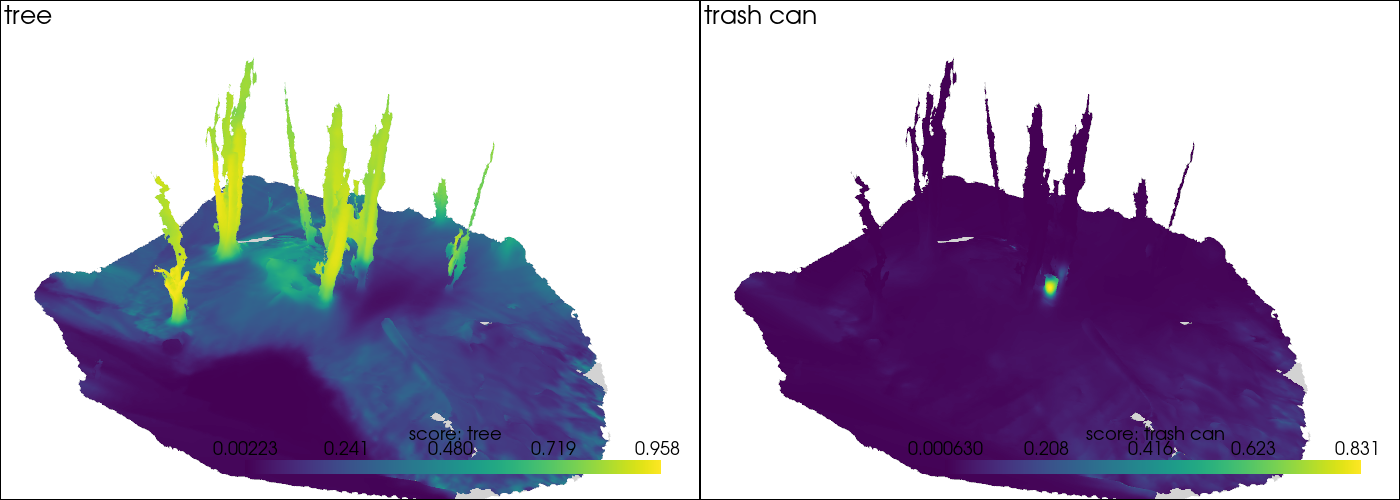

In [9]:
surface = pv.wrap(mesh)
plotter = pv.Plotter(shape=(1, 2), window_size=(1400, 500))

for col, (prompt, values) in enumerate([("tree", smoothed[:, 0]), ("trash can", smoothed[:, 1])]):
    plotter.subplot(0, col)
    plotter.add_text(prompt, font_size=10)
    plotter.add_mesh(
        surface.copy(),
        scalars=values,
        cmap="viridis",
        nan_color="lightgrey",
        lighting=False,
        scalar_bar_args={"title": f"score: {prompt}"},
    )

plotter.link_views()
apply_view(plotter, camera_view(cloud.extrinsics, vertices))
plotter.show()

The trunks should light up for "tree" while the ground stays dark. Each panel has its own color
range, so the trash can stands out even though its scores are lower.

## In a pipeline run

The `semantics` stage does all of the above for every keyframe and writes
`<backend>/semantics/talk2dino_lifted.zarr`. `max_epochs` caps the autoencoder fit.

With `segments` on (off by default), it also does section 4 and writes
`<backend>/semantics/mobilesamv2_segments.zarr`: a group per point, plus one per mesh vertex.

```yaml
semantics:
  enabled: true
  extractors: [talk2dino]
  max_epochs: 20
  segments:
    enabled: true
    features: talk2dino  # lifted features that veto merges and fill; null = none
```

To query interactively, open the scene in the viewer and pick the store from its Semantics menu:

```bash
python -m collab_splats.viewer local data/tutorial_scene/vggt_omega --port 8080
```